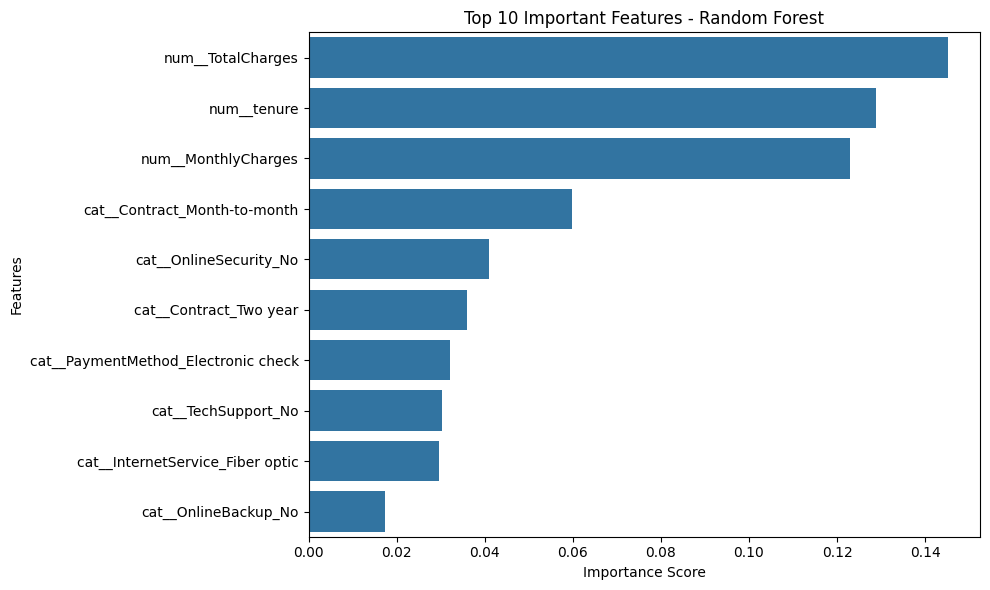

                                Feature  Importance
3                     num__TotalCharges    0.145203
1                           num__tenure    0.128772
2                   num__MonthlyCharges    0.122933
36         cat__Contract_Month-to-month    0.059912
18               cat__OnlineSecurity_No    0.040924
38               cat__Contract_Two year    0.035890
43  cat__PaymentMethod_Electronic check    0.032020
27                  cat__TechSupport_No    0.030411
16     cat__InternetService_Fiber optic    0.029572
21                 cat__OnlineBackup_No    0.017435


In [ ]:
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

importance = rf_model.named_steps['classifier'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
        'Importance': importance
        })

feature_importance = feature_importance.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature')

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print(feature_importance)

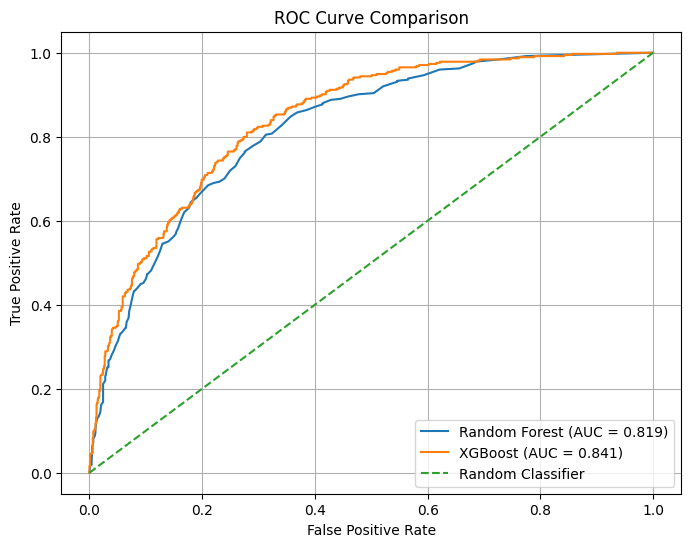

In [ ]:
rf_fpr, rf_tpr, _ = roc_curve(y_test, y_prob_rf)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {xgb_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

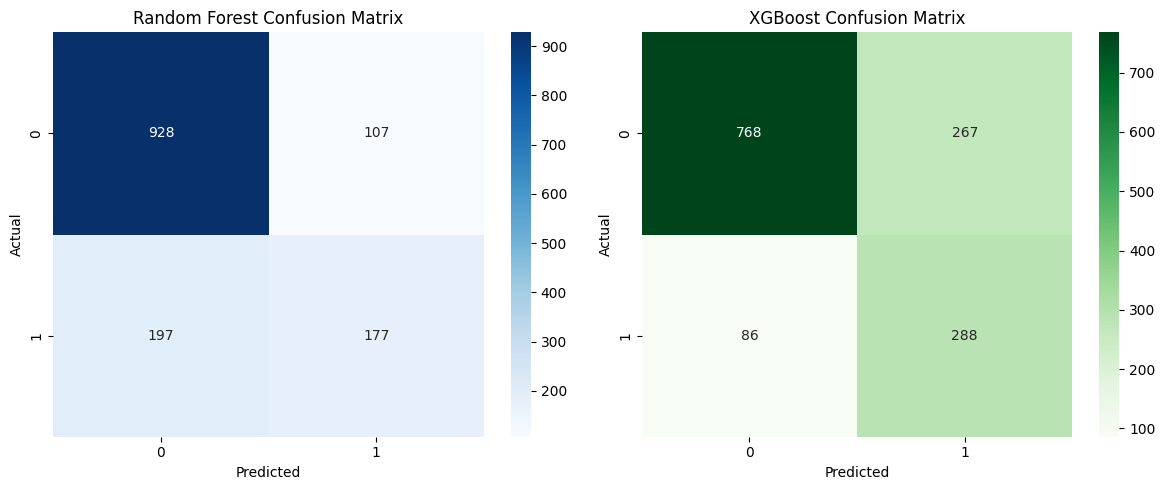

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("XGBoost Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
rf_auc = roc_auc_score(y_test, y_prob_rf)
xgb_auc = roc_auc_score(y_test, y_prob_xgb)

print("RANDOM FOREST RESULTS")
print("ROC-AUC:", rf_auc)
print(classification_report(y_test, y_pred_rf))

print("\nXGBOOST RESULTS")
print("ROC-AUC:", xgb_auc)
print(classification_report(y_test, y_pred_xgb))

RANDOM FOREST RESULTS
ROC-AUC: 0.8193249631868558
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1035
           1       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409


XGBOOST RESULTS
ROC-AUC: 0.8405383760882482
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [ ]:
rf_cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='roc_auc')

xgb_cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring='roc_auc')

print("Random Forest CV Scores:", rf_cv_scores)
print("Random Forest Average ROC-AUC:", rf_cv_scores.mean())

print("\nXGBoost CV Scores:", xgb_cv_scores)
print("XGBoost Average ROC-AUC:", xgb_cv_scores.mean())

Random Forest CV Scores: [0.84003845 0.83411088 0.82024017 0.81291503 0.80577338]
Random Forest Average ROC-AUC: 0.8226155835388651

XGBoost CV Scores: [0.8540465  0.85184714 0.84176724 0.82728661 0.82503144]
XGBoost Average ROC-AUC: 0.8399957866006261


In [ ]:
xgb_model = Pipeline(steps=[
      ('preprocessor', preprocessor),
          ('classifier', XGBClassifier(
                  n_estimators=100,
                          learning_rate=0.1,
                                  max_depth=5,
                                          scale_pos_weight=scale_weight,
                                                  eval_metric='logloss',
                                                          random_state=42
                                                              ))
                                                              ])

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Model Trained Successfully!")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))


XGBoost Model Trained Successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [ ]:
rf_model = Pipeline(steps=[
      ('preprocessor', preprocessor),
          ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
          ])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Model Trained Successfully!")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Model Trained Successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1035
           1       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(exclude=['object']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
        ])

categorical_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))
                ])

preprocessor = ColumnTransformer(transformers=[
                    ('num', numeric_transformer, numerical_cols),
                        ('cat', categorical_transformer, categorical_cols)
                        ])

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Categorical columns:", list(categorical_cols))
print("Numerical columns:", list(numerical_cols))

Training data shape: (5634, 19)
Testing data shape: (1409, 19)
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [ ]:
no_churn = (y == 0).sum()
yes_churn = (y == 1).sum()

scale_weight = no_churn / yes_churn

print("No Churn:", no_churn)
print("Yes Churn:", yes_churn)
print("Scale Pos Weight:", scale_weight)

No Churn: 5174
Yes Churn: 1869
Scale Pos Weight: 2.7683253076511503


Churn Count:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn Percentage:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


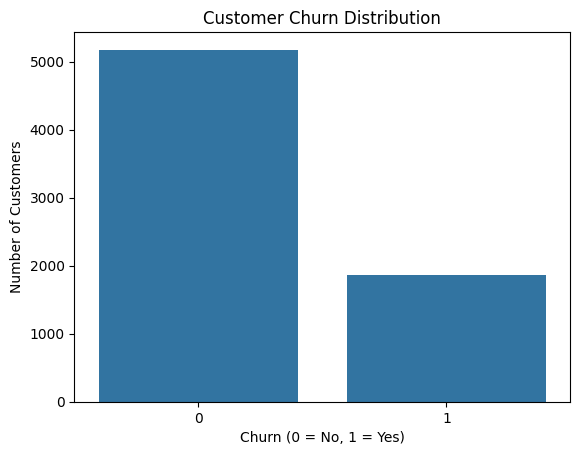

In [ ]:
print("Churn Count:")
print(y.value_counts())

print("\nChurn Percentage:")
print(y.value_counts(normalize=True) * 100)

sns.countplot(x=y)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
df.shape

(7043, 20)

In [ ]:
if 'customerID' in df.columns:
      df = df.drop('customerID', axis=1)

      print("CustomerID handled successfully!")
      print(df.columns)

In [ ]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df['TotalCharges'].dtype

dtype('float64')

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

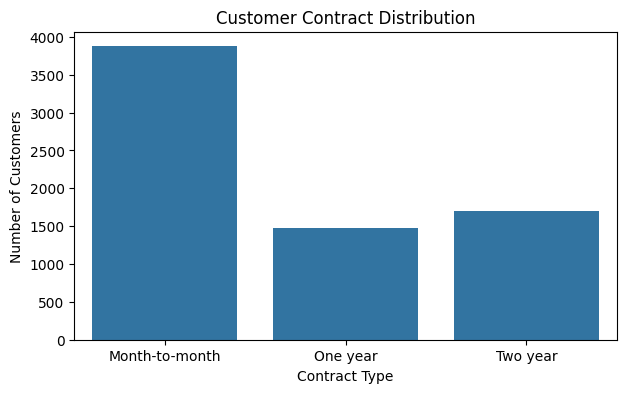

In [ ]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='Contract')

plt.title('Customer Contract Distribution')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
df['Contract'].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


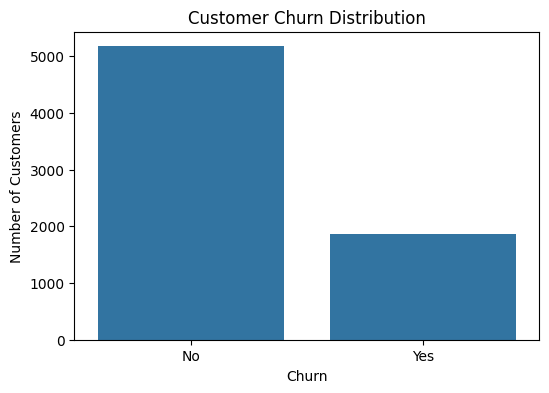

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
df['Churn'].value_counts()
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [ ]:
df.shape
df.columns
df.info()
df.describe()
df.describe(include='all')
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier